# Ejercicio 1 - Selección y preparación de series MRI


## 1. Objetivo


Este notebook tiene como objetivo seleccionar una única serie de
resonancia magnética por estudio para la etapa posterior de
clasificación multietiqueta.

A partir de los 500 estudios con etiquetas débiles y de los 58 estudios
GOLD, se analiza la disponibilidad de planos y secuencias MRI. Se
selecciona como configuración principal una secuencia sagital sensible
a líquido con supresión de grasa, y posteriormente se resuelven los
casos que presentan múltiples series candidatas mediante metadatos DICOM.

El resultado final es un manifiesto reproducible con una única serie
seleccionada por estudio.

## 2. Carga de metadatos y subconjunto weak

In [81]:
import pandas as pd
import os

COMP_PATH = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train_series_path = os.path.join(
    COMP_PATH,
    "train_series.csv"
)

series = pd.read_csv(train_series_path)

print("Dimensiones train_series:", series.shape)

print("\nColumnas:")
print(series.columns.tolist())

display(series.head(10))

Dimensiones train_series: (24371, 5)

Columnas:
['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal
5,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.27845969797953115400...,0,0,Sagittal
6,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.72137122913943091996...,1,1,Sagittal
7,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.83327574802189551711...,1,1,Axial
8,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.87374594163896635184...,0,0,Coronal
9,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.99023014295026495734...,1,1,Coronal


In [82]:
WEAK_PATH = (
    "/kaggle/input/datasets/mariomasias/"
    "weak-500-final/weak_500_final.csv"
)

weak_500 = pd.read_csv(WEAK_PATH)

print("Dimensiones:", weak_500.shape)
print("Estudios únicos:", weak_500["StudyInstanceUID"].nunique())

display(
    weak_500[
        ["StudyInstanceUID", "Idioma"]
    ].head()
)

Dimensiones: (500, 30)
Estudios únicos: 500


,StudyInstanceUID,Idioma
0,1.2.826.0.1.3680043.8.498.91660278231317256353...,bg
1,1.2.826.0.1.3680043.8.498.36648377536792309029...,en
2,1.2.826.0.1.3680043.8.498.91742054227008690570...,en
3,1.2.826.0.1.3680043.8.498.91940000162714863613...,es
4,1.2.826.0.1.3680043.8.498.10029520033957968044...,en


In [83]:
series["StudyInstanceUID"] = (
    series["StudyInstanceUID"].astype(str)
)

weak_500["StudyInstanceUID"] = (
    weak_500["StudyInstanceUID"].astype(str)
)

## 3. Correspondencia entre estudios y series MRI

In [84]:
series_500 = series[
    series["StudyInstanceUID"].isin(
        weak_500["StudyInstanceUID"]
    )
].copy()

print("=== CRUCE DE LOS 500 WEAK ===")

print(
    "Estudios encontrados:",
    series_500["StudyInstanceUID"].nunique()
)

print(
    "Series encontradas:",
    series_500["SeriesInstanceUID"].nunique()
)

faltantes = set(
    weak_500["StudyInstanceUID"]
) - set(
    series_500["StudyInstanceUID"]
)

print("Estudios faltantes:", len(faltantes))

=== CRUCE DE LOS 500 WEAK ===
Estudios encontrados: 500
Series encontradas: 2762
Estudios faltantes: 0


In [85]:
series_por_estudio = (
    series_500
    .groupby("StudyInstanceUID")
    ["SeriesInstanceUID"]
    .nunique()
)

display(
    series_por_estudio.describe()
)

count    500.000000
mean       5.524000
std        1.474372
min        4.000000
25%        5.000000
50%        5.000000
75%        6.000000
max       13.000000
Name: SeriesInstanceUID, dtype: float64

## 4. Análisis de cobertura por plano y secuencia

Se evaluó la disponibilidad de las diferentes combinaciones de plano,
sensibilidad a líquido y supresión grasa tanto en los 500 estudios con
etiquetas débiles como en los 58 estudios GOLD.

El objetivo es seleccionar una secuencia con alta cobertura en ambos
conjuntos y adecuada para la clasificación multietiqueta.

In [86]:
resumen_secuencias_500 = (
    series_500
    .groupby(
        [
            "Anatomical_Plane",
            "Fluid_Sensitive",
            "Fat_Suppression"
        ]
    )
    .agg(
        Series=("SeriesInstanceUID", "nunique"),
        Estudios=("StudyInstanceUID", "nunique")
    )
    .reset_index()
)

resumen_secuencias_500["Cobertura (%)"] = (
    100 *
    resumen_secuencias_500["Estudios"]
    / len(weak_500)
).round(1)

resumen_secuencias_500 = (
    resumen_secuencias_500
    .sort_values(
        ["Estudios", "Series"],
        ascending=False
    )
)

display(resumen_secuencias_500)

,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Series,Estudios,Cobertura (%)
1,Axial,1,1,529,500,100.0
3,Coronal,1,1,544,498,99.6
5,Sagittal,1,1,527,490,98.0
4,Sagittal,0,0,581,489,97.8
2,Coronal,0,0,435,394,78.8
0,Axial,0,0,146,102,20.4


In [87]:
train_path = os.path.join(
    COMP_PATH,
    "train.csv"
)

train = pd.read_csv(train_path)

labels = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

gold_mask = train[labels].notna().all(axis=1)

gold = train[gold_mask].copy()

gold["StudyInstanceUID"] = (
    gold["StudyInstanceUID"].astype(str)
)

print("Estudios GOLD:", len(gold))



Estudios GOLD: 58


In [88]:
series_gold = series[
    series["StudyInstanceUID"].isin(
        gold["StudyInstanceUID"]
    )
].copy()

print(
    "GOLD encontrados:",
    series_gold["StudyInstanceUID"].nunique()
)

print(
    "Series GOLD:",
    series_gold["SeriesInstanceUID"].nunique()
)

GOLD encontrados: 58
Series GOLD: 336


In [89]:
resumen_secuencias_gold = (
    series_gold
    .groupby(
        [
            "Anatomical_Plane",
            "Fluid_Sensitive",
            "Fat_Suppression"
        ]
    )
    .agg(
        Series=("SeriesInstanceUID", "nunique"),
        Estudios=("StudyInstanceUID", "nunique")
    )
    .reset_index()
)

resumen_secuencias_gold["Cobertura (%)"] = (
    100 *
    resumen_secuencias_gold["Estudios"]
    / len(gold)
).round(1)

resumen_secuencias_gold = (
    resumen_secuencias_gold
    .sort_values(
        "Estudios",
        ascending=False
    )
)

display(resumen_secuencias_gold)

,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Series,Estudios,Cobertura (%)
1,Axial,1,1,63,58,100.0
4,Sagittal,0,0,72,57,98.3
5,Sagittal,1,1,64,56,96.6
3,Coronal,1,1,65,56,96.6
2,Coronal,0,0,54,45,77.6
0,Axial,0,0,18,13,22.4


## 5. Selección de la secuencia principal

Se seleccionó como configuración principal:

**Sagittal + Fluid Sensitive + Fat Suppression**

Esta configuración está disponible en 490 de los 500 estudios con
etiquetas débiles (98.0 %) y en 56 de los 58 estudios GOLD (96.6 %).

La selección permite reducir considerablemente el volumen de imágenes
a procesar y mantener una cobertura elevada en ambos conjuntos.

In [90]:
# ============================================================
# SECUENCIA PRINCIPAL
# Sagittal + Fluid Sensitive + Fat Suppression
# ============================================================

series_weak_sag = series_500[
    (series_500["Anatomical_Plane"] == "Sagittal") &
    (series_500["Fluid_Sensitive"] == 1) &
    (series_500["Fat_Suppression"] == 1)
].copy()

series_gold_sag = series_gold[
    (series_gold["Anatomical_Plane"] == "Sagittal") &
    (series_gold["Fluid_Sensitive"] == 1) &
    (series_gold["Fat_Suppression"] == 1)
].copy()

print("=== SAGITTAL FLUID-SENSITIVE + FAT-SUPPRESSION ===")

print(
    "Weak:",
    series_weak_sag["StudyInstanceUID"].nunique(),
    "/ 500 estudios"
)

print(
    "GOLD:",
    series_gold_sag["StudyInstanceUID"].nunique(),
    "/ 58 estudios"
)

print(
    "\nSeries weak:",
    series_weak_sag["SeriesInstanceUID"].nunique()
)

print(
    "Series GOLD:",
    series_gold_sag["SeriesInstanceUID"].nunique()
)

=== SAGITTAL FLUID-SENSITIVE + FAT-SUPPRESSION ===
Weak: 490 / 500 estudios
GOLD: 56 / 58 estudios

Series weak: 527
Series GOLD: 64


In [91]:
multi_weak = (
    series_weak_sag
    .groupby("StudyInstanceUID")
    ["SeriesInstanceUID"]
    .nunique()
)

multi_gold = (
    series_gold_sag
    .groupby("StudyInstanceUID")
    ["SeriesInstanceUID"]
    .nunique()
)

print("=== WEAK ===")
print(multi_weak.value_counts().sort_index())

print("\nEstudios weak con más de una serie candidata:")
print((multi_weak > 1).sum())

print("\n=== GOLD ===")
print(multi_gold.value_counts().sort_index())

print("\nEstudios GOLD con más de una serie candidata:")
print((multi_gold > 1).sum())

=== WEAK ===
SeriesInstanceUID
1    453
2     37
Name: count, dtype: int64

Estudios weak con más de una serie candidata:
37

=== GOLD ===
SeriesInstanceUID
1    48
2     8
Name: count, dtype: int64

Estudios GOLD con más de una serie candidata:
8


In [92]:
TRAIN_DICOM_DIR = os.path.join(
    COMP_PATH,
    "train_series"
)

print("Ruta:")
print(TRAIN_DICOM_DIR)

print("\nExiste:", os.path.exists(TRAIN_DICOM_DIR))

if os.path.exists(TRAIN_DICOM_DIR):
    estudios_dirs = os.listdir(TRAIN_DICOM_DIR)

    print(
        "\nNúmero de carpetas en train_series:",
        len(estudios_dirs)
    )

    print("\nPrimeras 5:")
    for x in estudios_dirs[:5]:
        print(x)

Ruta:
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series

Existe: True

Número de carpetas en train_series: 4407

Primeras 5:
1.2.826.0.1.3680043.8.498.10843463954622076609489312662891432839
1.2.826.0.1.3680043.8.498.11425683153901568541658945026861110110
1.2.826.0.1.3680043.8.498.68524920268469128133836299591793117756
1.2.826.0.1.3680043.8.498.65222333228514862688331581862087607325
1.2.826.0.1.3680043.8.498.27653320597564308144389724321115208375


### Estudios sin la secuencia seleccionada

La configuración **Sagittal + Fluid Sensitive + Fat Suppression**
no está disponible en 10 de los 500 estudios con etiquetas débiles
ni en 2 de los 58 estudios GOLD.

Por este motivo, el experimento principal basado en imágenes sagitales
utilizará **490 estudios WEAK y 56 estudios GOLD**.

Los estudios GOLD restantes no se eliminan del proyecto, ya que pueden
ser utilizados posteriormente en experimentos con otras secuencias o
planos que sí estén disponibles, como el plano axial.

## 6. Inventario de series DICOM candidatas

In [93]:
# ============================================================
# INVENTARIO DE SERIES SAGITALES CANDIDATAS
# ============================================================

import os
import pandas as pd
import numpy as np
import pydicom

candidatas_sag = pd.concat([
    series_weak_sag.assign(Grupo="WEAK"),
    series_gold_sag.assign(Grupo="GOLD")
], ignore_index=True)

def inspeccionar_serie(row):

    study_uid = row["StudyInstanceUID"]
    series_uid = row["SeriesInstanceUID"]

    ruta = os.path.join(
        TRAIN_DICOM_DIR,
        study_uid,
        series_uid
    )

    archivos = [
        f for f in os.listdir(ruta)
        if f.lower().endswith(".dcm")
    ]

    n_slices = len(archivos)

    # Tamaño total de la serie
    bytes_total = sum(
        os.path.getsize(
            os.path.join(ruta, f)
        )
        for f in archivos
    )

    # Leer SOLO cabecera de un DICOM
    # No carga PixelData
    archivo_ejemplo = os.path.join(
        ruta,
        archivos[0]
    )

    ds = pydicom.dcmread(
        archivo_ejemplo,
        stop_before_pixels=True,
        force=True
    )

    return pd.Series({
        "Grupo": row["Grupo"],
        "StudyInstanceUID": study_uid,
        "SeriesInstanceUID": series_uid,
        "N_Slices": n_slices,
        "Tamaño_MB": bytes_total / (1024**2),
        "Rows": getattr(ds, "Rows", np.nan),
        "Columns": getattr(ds, "Columns", np.nan),
        "SliceThickness": getattr(
            ds,
            "SliceThickness",
            np.nan
        ),
        "SpacingBetweenSlices": getattr(
            ds,
            "SpacingBetweenSlices",
            np.nan
        ),
        "SeriesDescription": getattr(
            ds,
            "SeriesDescription",
            ""
        ),
        "ProtocolName": getattr(
            ds,
            "ProtocolName",
            ""
        ),
        "RepetitionTime": getattr(
            ds,
            "RepetitionTime",
            np.nan
        ),
        "EchoTime": getattr(
            ds,
            "EchoTime",
            np.nan
        )
    })


inventario_sag = candidatas_sag.apply(
    inspeccionar_serie,
    axis=1
)

print("Series analizadas:", len(inventario_sag))

display(inventario_sag.head())

Series analizadas: 591


,Grupo,StudyInstanceUID,SeriesInstanceUID,N_Slices,Tamaño_MB,Rows,Columns,SliceThickness,SpacingBetweenSlices,SeriesDescription,ProtocolName,RepetitionTime,EchoTime
0,WEAK,1.2.826.0.1.3680043.8.498.10029520033957968044...,1.2.826.0.1.3680043.8.498.12283902861056341541...,26,20.348200,640,640,3.0,3.6,LT_pd_tse_fs_sag,,3550.000000,36.0
1,WEAK,1.2.826.0.1.3680043.8.498.10061120822929703004...,1.2.826.0.1.3680043.8.498.52617317497828611151...,30,16.001928,528,528,3.0,3.5,PDW_SPAIR,,3875.636963,30.0
2,WEAK,1.2.826.0.1.3680043.8.498.10087350795575215080...,1.2.826.0.1.3680043.8.498.96012886433868321293...,35,17.550863,512,512,3.0,3.3,DummySeriesDesc!,,3143.979004,35.0
3,WEAK,1.2.826.0.1.3680043.8.498.10155611590208164695...,1.2.826.0.1.3680043.8.498.62105522526870664598...,32,14.109434,480,480,3.0,3.3,RT.SAG PDW_TSE_SPAIR,,3426.484863,20.0
4,WEAK,1.2.826.0.1.3680043.8.498.10161011217774350674...,1.2.826.0.1.3680043.8.498.10027425647703671514...,32,16.046444,512,512,3.0,3.3,DummySeriesDesc!,,2794.646484,35.0


In [94]:
print("=== NÚMERO DE CORTES ===")

display(
    inventario_sag["N_Slices"].describe()
)

print("\n=== TAMAÑO DE SERIES ===")

display(
    inventario_sag["Tamaño_MB"].describe()
)

print(
    "\nTamaño TOTAL de todas las series sagitales candidatas:",
    round(inventario_sag["Tamaño_MB"].sum() / 1024, 2),
    "GB"
)

=== NÚMERO DE CORTES ===


count    591.000000
mean      30.935702
std       21.544182
min       15.000000
25%       26.000000
50%       29.000000
75%       33.000000
max      320.000000
Name: N_Slices, dtype: float64


=== TAMAÑO DE SERIES ===


count    591.000000
mean      18.390251
std       20.726951
min        2.526501
25%        8.198589
50%       14.039623
75%       22.564400
max      250.506376
Name: Tamaño_MB, dtype: float64


Tamaño TOTAL de todas las series sagitales candidatas: 10.61 GB


## 7. Análisis de múltiples series por estudio

In [95]:
conteo_candidatas = (
    inventario_sag
    .groupby("StudyInstanceUID")
    ["SeriesInstanceUID"]
    .nunique()
)

uids_duplicados = conteo_candidatas[
    conteo_candidatas > 1
].index

duplicados_sag = (
    inventario_sag[
        inventario_sag["StudyInstanceUID"].isin(
            uids_duplicados
        )
    ]
    .sort_values(
        [
            "StudyInstanceUID",
            "N_Slices"
        ]
    )
)

print(
    "Estudios con más de una serie:",
    len(uids_duplicados)
)

display(
    duplicados_sag[
        [
            "Grupo",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "N_Slices",
            "Tamaño_MB",
            "Rows",
            "Columns",
            "SliceThickness",
            "SpacingBetweenSlices",
            "SeriesDescription",
            "ProtocolName"
        ]
    ].head(30)
)

Estudios con más de una serie: 45


,Grupo,StudyInstanceUID,SeriesInstanceUID,N_Slices,Tamaño_MB,Rows,Columns,SliceThickness,SpacingBetweenSlices,SeriesDescription,ProtocolName
7,WEAK,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.59647521704250318192...,30,60.043259,1024,1024,4.0,4.50,Sag T2 FSE FS DL,
8,WEAK,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.77133842585616604446...,30,60.043144,1024,1024,4.0,4.50,ORIG Sag T2 FSE FS DL,
26,WEAK,1.2.826.0.1.3680043.8.498.10495281520660483987...,1.2.826.0.1.3680043.8.498.25961718135768885603...,24,3.033545,256,256,4.0,4.52,REPEAT LOWER SAG T2 FS,
25,WEAK,1.2.826.0.1.3680043.8.498.10495281520660483987...,1.2.826.0.1.3680043.8.498.12529748410625327431...,30,3.791574,256,256,4.0,4.52,SAG T2 FS,
33,WEAK,1.2.826.0.1.3680043.8.498.10762741411077456296...,1.2.826.0.1.3680043.8.498.11126851762792686626...,24,12.031525,512,512,3.0,4.00,,
34,WEAK,1.2.826.0.1.3680043.8.498.10762741411077456296...,1.2.826.0.1.3680043.8.498.11993452072485760706...,24,12.031525,512,512,3.0,4.00,,
35,WEAK,1.2.826.0.1.3680043.8.498.10774147135673365265...,1.2.826.0.1.3680043.8.498.12482625042937463915...,22,11.022909,512,512,4.0,NaN,Sag T2 FS,
36,WEAK,1.2.826.0.1.3680043.8.498.10774147135673365265...,1.2.826.0.1.3680043.8.498.38081740384783516819...,22,11.022783,512,512,4.0,NaN,Sag PD FS,
45,WEAK,1.2.826.0.1.3680043.8.498.11249981834802444119...,1.2.826.0.1.3680043.8.498.23261656997277612738...,25,50.035875,1024,1024,3.0,3.60,DummySeriesDesc!,
46,WEAK,1.2.826.0.1.3680043.8.498.11249981834802444119...,1.2.826.0.1.3680043.8.498.71778369224970399806...,25,50.035875,1024,1024,3.0,3.60,DummySeriesDesc!,


In [96]:
weak_sin_sag = weak_500[
    ~weak_500["StudyInstanceUID"].isin(
        series_weak_sag["StudyInstanceUID"]
    )
].copy()

gold_sin_sag = gold[
    ~gold["StudyInstanceUID"].isin(
        series_gold_sag["StudyInstanceUID"]
    )
].copy()

print(
    "WEAK sin Sagittal FS:",
    len(weak_sin_sag)
)

print(
    "GOLD sin Sagittal FS:",
    len(gold_sin_sag)
)

print("\nGOLD sin Sagittal FS:")
display(
    gold_sin_sag[
        ["StudyInstanceUID"] + labels
    ]
)

WEAK sin Sagittal FS: 10
GOLD sin Sagittal FS: 2

GOLD sin Sagittal FS:


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
3425,1.2.826.0.1.3680043.8.498.73926443729786165628...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
4302,1.2.826.0.1.3680043.8.498.97274720257634584071...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0


## 8. Clasificación y selección de una serie por estudio

Algunos estudios presentan más de una serie sagital compatible.
Por ello, se analizan las descripciones de las secuencias y parámetros
DICOM como `EchoTime` para caracterizar las adquisiciones y seleccionar
una única serie por estudio mediante una regla reproducible.

In [97]:
# ============================================================
# CLASIFICAR SERIES SAGITALES SEGÚN DESCRIPCIÓN
# ============================================================

def clasificar_serie_sag(row):

    texto = (
        str(row["SeriesDescription"]) + " " +
        str(row["ProtocolName"])
    ).lower()

    # Detectar PD
    es_pd = any(
        x in texto
        for x in [
            " pd ",
            "pdw",
            "_pd",
            "pd_",
            "pd fs",
            "pd f/s",
            "pd fat",
            "proton"
        ]
    )

    # Detectar T2
    es_t2 = any(
        x in texto
        for x in [
            "t2",
            "t2w"
        ]
    )

    # Series que preferimos evitar si existe alternativa
    es_repeat = any(
        x in texto
        for x in [
            "repeat",
            "lower",
            "orig "
        ]
    )

    if es_pd:
        tipo = "PD"
    elif es_t2:
        tipo = "T2"
    else:
        tipo = "OTRO"

    return pd.Series({
        "Tipo_Secuencia": tipo,
        "Es_Repeat": es_repeat
    })


clasificacion = inventario_sag.apply(
    clasificar_serie_sag,
    axis=1
)

inventario_sag = pd.concat(
    [
        inventario_sag,
        clasificacion
    ],
    axis=1
)

print("=== TIPO DE SECUENCIA ===")

print(
    inventario_sag["Tipo_Secuencia"]
    .value_counts()
)

print("\n=== REPEAT / ORIG / LOWER ===")

print(
    inventario_sag["Es_Repeat"]
    .value_counts()
)

=== TIPO DE SECUENCIA ===
Tipo_Secuencia
PD      226
OTRO    198
T2      167
Name: count, dtype: int64

=== REPEAT / ORIG / LOWER ===
Es_Repeat
False    588
True       3
Name: count, dtype: int64


In [98]:
print("=== DESCRIPCIONES MÁS FRECUENTES ===")

display(
    inventario_sag[
        [
            "SeriesDescription",
            "Tipo_Secuencia"
        ]
    ]
    .value_counts()
    .head(30)
)

=== DESCRIPCIONES MÁS FRECUENTES ===


SeriesDescription                   Tipo_Secuencia
DummySeriesDesc!                    OTRO              119
                                    OTRO               38
pd_tse_fs_sag_320                   PD                 33
SAG T2 FS                           T2                 32
PDW_TSE_SPAIR_Sag                   PD                 24
Sag T2 FSE FS                       T2                 24
Sag PD FSE FS                       PD                 22
Water: SMART FAT                    OTRO               15
SAG T2 FS_sm_AIRS                   T2                 14
pd_tse_fs_sag_np                    PD                 14
RT.Sag_PDW_TSE_SPAIR_Sag            PD                 13
pd_tse_fs_sag                       PD                 13
SAG T2 FS RIGHT                     T2                 13
LT.Sag_PDW_TSE_SPAIR_Sag            PD                 11
Sag T2 FSE FS_sm_AIRS               T2                 11
Sag PD FS                           PD                 10
pd_tse_fs_sag_416_p2_

In [99]:
display(
    inventario_sag.sort_values(
        "N_Slices",
        ascending=False
    )[
        [
            "Grupo",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "N_Slices",
            "Tamaño_MB",
            "Rows",
            "Columns",
            "SliceThickness",
            "SpacingBetweenSlices",
            "SeriesDescription",
            "ProtocolName",
            "RepetitionTime",
            "EchoTime"
        ]
    ].head(15)
)

,Grupo,StudyInstanceUID,SeriesInstanceUID,N_Slices,Tamaño_MB,Rows,Columns,SliceThickness,SpacingBetweenSlices,SeriesDescription,ProtocolName,RepetitionTime,EchoTime
282,WEAK,1.2.826.0.1.3680043.8.498.47094981922544354899...,1.2.826.0.1.3680043.8.498.48845313136724096783...,320,250.478893,640,640,0.8,0.4,SAG 3D_VIEW_PD_SPAIR_HR R,,1100.0,23.000
344,WEAK,1.2.826.0.1.3680043.8.498.62030472630193758412...,1.2.826.0.1.3680043.8.498.34596199416494017047...,320,250.478899,640,640,0.8,0.4,SAG 3D_VIEW_PD_SPAIR_HR L,,1100.0,23.000
567,GOLD,1.2.826.0.1.3680043.8.498.48946580946665031852...,1.2.826.0.1.3680043.8.498.31457592019990349918...,320,250.506376,640,640,0.8,0.4,SAG 3D_VIEW_PD_SPAIR_HR L,,1100.0,23.000
311,WEAK,1.2.826.0.1.3680043.8.498.54761306437713414745...,1.2.826.0.1.3680043.8.498.10271572304980795272...,54,27.076624,512,512,2.0,2.2,Sag PD FSE FS,,3517.0,39.320
48,WEAK,1.2.826.0.1.3680043.8.498.11276674006815021828...,1.2.826.0.1.3680043.8.498.12606790664427607668...,53,26.575138,512,512,2.0,2.2,Sag PD FSE FS,,3735.0,39.440
165,WEAK,1.2.826.0.1.3680043.8.498.21012635480218712816...,1.2.826.0.1.3680043.8.498.11252550908122112963...,53,26.575222,512,512,2.0,2.2,Sag PD FSE FS,,3765.0,39.800
5,WEAK,1.2.826.0.1.3680043.8.498.10162168547770229150...,1.2.826.0.1.3680043.8.498.22411188800278791134...,53,26.575153,512,512,2.0,2.2,Sag PD FSE FS,,3759.0,39.720
234,WEAK,1.2.826.0.1.3680043.8.498.35942316720546803304...,1.2.826.0.1.3680043.8.498.62544509211062204323...,53,26.575800,512,512,2.0,2.2,Sag PD FSE FS,,3734.0,39.400
185,WEAK,1.2.826.0.1.3680043.8.498.25512240159357553134...,1.2.826.0.1.3680043.8.498.17190650102239792654...,52,26.073708,512,512,2.0,2.2,Sag PD FSE FS,,3644.0,40.080
32,WEAK,1.2.826.0.1.3680043.8.498.10650751856837517181...,1.2.826.0.1.3680043.8.498.69576913252372448353...,50,25.071486,512,512,2.0,2.2,Sag PD FSE FS,,3475.0,39.640


In [100]:
# ============================================================
# COMPARAR ECHO TIME ENTRE PD, T2 Y OTROS
# ============================================================

display(
    inventario_sag
    .groupby("Tipo_Secuencia")[
        ["RepetitionTime", "EchoTime"]
    ]
    .describe()
)

RepetitionTime                                         \
                        count         mean          std          min   
Tipo_Secuencia                                                         
OTRO                    198.0  2870.076712   819.890653  1608.195557   
PD                      213.0  3177.566687   952.753815  1100.000000   
T2                      154.0  3614.324035  1161.910485  1996.000000   

                                                              EchoTime  \
                        25%          50%          75%     max    count   
Tipo_Secuencia                                                           
OTRO            2445.317078  2619.987061  3143.979004  6159.0    198.0   
PD              2566.670000  3264.790283  3560.737549  7160.0    213.0   
T2              3000.000000  3462.000000  3816.000000  8640.0    154.0   

                                                                              
                     mean        std     min     25%     50%     75%     max  
Tipo_Secuencia                                                                
OTRO            39.329394  11.231137  12.000  33.000  35.000  39.207  73.520  
PD              32.419887   6.914066  14.000  28.992  30.000  39.520  50.000  
T2              63.709532  14.190497  29.472  53.000  65.804  76.000  85.792

In [101]:
print("=== ECHO TIME POR TIPO ===")

for tipo in ["PD", "T2", "OTRO"]:

    subset = inventario_sag[
        inventario_sag["Tipo_Secuencia"] == tipo
    ]

    print(f"\n--- {tipo} ---")

    print(
        subset["EchoTime"]
        .describe()
    )

=== ECHO TIME POR TIPO ===

--- PD ---
count    213.000000
mean      32.419887
std        6.914066
min       14.000000
25%       28.992000
50%       30.000000
75%       39.520000
max       50.000000
Name: EchoTime, dtype: float64

--- T2 ---
count    154.000000
mean      63.709532
std       14.190497
min       29.472000
25%       53.000000
50%       65.804000
75%       76.000000
max       85.792000
Name: EchoTime, dtype: float64

--- OTRO ---
count    198.000000
mean      39.329394
std       11.231137
min       12.000000
25%       33.000000
50%       35.000000
75%       39.207000
max       73.520000
Name: EchoTime, dtype: float64


In [102]:
print("\n=== OTROS ORDENADOS POR ECHO TIME ===")

display(
    inventario_sag[
        inventario_sag["Tipo_Secuencia"] == "OTRO"
    ][
        [
            "SeriesDescription",
            "RepetitionTime",
            "EchoTime",
            "N_Slices",
            "SliceThickness",
            "SpacingBetweenSlices"
        ]
    ]
    .sort_values("EchoTime")
    .head(40)
)


=== OTROS ORDENADOS POR ECHO TIME ===


,SeriesDescription,RepetitionTime,EchoTime,N_Slices,SliceThickness,SpacingBetweenSlices
540,SAG DP SPIR,2000.000000,12.000,20,4.0,5.290
539,SAG DP SPIR,1608.195557,20.000,22,3.5,4.500
578,SAG DP SPIR,1613.310547,20.000,22,3.5,4.500
480,DummySeriesDesc!,2461.000000,28.224,30,3.0,3.800
45,DummySeriesDesc!,2230.000000,29.920,25,3.0,3.600
42,,2063.000000,30.000,26,3.5,4.000
69,,2142.000000,30.000,27,3.5,4.000
78,DummySeriesDesc!,2098.977295,30.000,27,3.5,3.850
267,DummySeriesDesc!,2619.978027,30.000,30,3.0,3.300
268,DummySeriesDesc!,2596.008789,30.000,33,3.0,3.300


In [103]:
display(
    inventario_sag[
        inventario_sag["Tipo_Secuencia"] == "OTRO"
    ][
        [
            "SeriesDescription",
            "RepetitionTime",
            "EchoTime",
            "N_Slices",
            "SliceThickness",
            "SpacingBetweenSlices"
        ]
    ]
    .sort_values(
        "EchoTime",
        ascending=False
    )
    .head(40)
)

,SeriesDescription,RepetitionTime,EchoTime,N_Slices,SliceThickness,SpacingBetweenSlices
46,DummySeriesDesc!,5911.000000,73.520,25,3.0,3.60
61,DummySeriesDesc!,4909.000000,72.880,28,3.0,3.60
363,DummySeriesDesc!,5179.000000,70.992,28,3.0,3.50
235,DummySeriesDesc!,5640.000000,70.560,30,3.0,3.50
357,DummySeriesDesc!,3850.000000,70.000,27,4.0,4.40
305,DummySeriesDesc!,4130.000000,70.000,29,3.0,3.45
252,DummySeriesDesc!,5562.000000,68.976,28,3.0,3.50
150,DummySeriesDesc!,6159.000000,67.392,30,3.0,3.50
177,DummySeriesDesc!,5527.000000,67.248,28,3.0,3.50
479,DummySeriesDesc!,5900.000000,66.672,30,3.0,3.80


### Clasificación de las secuencias

Las descripciones DICOM permitieron identificar directamente muchas
series PD y T2. Sin embargo, algunas series presentaban descripciones
genéricas o incompletas.

Para estos casos se utilizó `EchoTime` como criterio auxiliar. A partir
de la distribución observada en las series identificadas explícitamente,
se definieron las siguientes categorías:

- `PD`: identificación explícita de PD.
- `T2`: identificación explícita de T2.
- `PD_like`: descripción ambigua con TE ≤ 45 ms.
- `T2_like`: descripción ambigua con TE ≥ 50 ms.
- `AMBIGUO`: casos intermedios o sin información suficiente.

Esta clasificación se utiliza únicamente para seleccionar de forma
reproducible una serie por estudio y no representa una etiqueta clínica.

In [104]:
# ============================================================
# CLASIFICACIÓN FINAL DE SERIES SAGITALES
# ============================================================

def clasificar_serie_final(row):

    texto = (
        str(row["SeriesDescription"]) + " " +
        str(row["ProtocolName"])
    ).lower()

    te = row["EchoTime"]

    # -------------------------
    # 1. Identificación explícita
    # -------------------------

    es_pd = (
        "pd" in texto
        or "proton" in texto
        or " dp " in f" {texto} "
    )

    es_t2 = (
        "t2" in texto
    )

    # -------------------------
    # 2. Evitar adquisiciones alternativas
    # -------------------------

    es_repeat = any(
        x in texto
        for x in [
            "repeat",
            "lower",
            "orig "
        ]
    )

    # -------------------------
    # 3. Clasificación
    # -------------------------

    if es_pd:
        tipo = "PD"

    elif es_t2:
        tipo = "T2"

    else:
        # Inferencia conservadora usando EchoTime
        if pd.notna(te):

            if te <= 45:
                tipo = "PD_like"

            elif te >= 50:
                tipo = "T2_like"

            else:
                tipo = "AMBIGUO"

        else:
            tipo = "AMBIGUO"

    return pd.Series({
        "Tipo_Final": tipo,
        "Es_Repeat_Final": es_repeat
    })


clasificacion_final = inventario_sag.apply(
    clasificar_serie_final,
    axis=1
)

inventario_sag = pd.concat(
    [
        inventario_sag,
        clasificacion_final
    ],
    axis=1
)

print("=== CLASIFICACIÓN FINAL ===")

print(
    inventario_sag["Tipo_Final"]
    .value_counts()
)

print("\nSeries alternativas/repetidas:")

print(
    inventario_sag["Es_Repeat_Final"]
    .value_counts()
)

=== CLASIFICACIÓN FINAL ===
Tipo_Final
PD         230
T2         167
PD_like    147
T2_like     43
AMBIGUO      4
Name: count, dtype: int64

Series alternativas/repetidas:
Es_Repeat_Final
False    588
True       3
Name: count, dtype: int64


In [105]:
# ============================================================
# SELECCIONAR UNA SERIE SAGITAL POR ESTUDIO
# ============================================================

prioridad_tipo = {
    "PD": 1,
    "T2": 2,
    "PD_like": 3,
    "T2_like": 4,
    "AMBIGUO": 5
}

inventario_sag["Prioridad_Tipo"] = (
    inventario_sag["Tipo_Final"]
    .map(prioridad_tipo)
)

# Las series normales tienen prioridad
# sobre repeat/orig/lower
inventario_sag["Prioridad_Repeat"] = (
    inventario_sag["Es_Repeat_Final"]
    .astype(int)
)

seleccion_sag = (
    inventario_sag
    .sort_values(
        [
            "StudyInstanceUID",
            "Prioridad_Repeat",
            "Prioridad_Tipo",
            "SeriesInstanceUID"
        ]
    )
    .drop_duplicates(
        subset="StudyInstanceUID",
        keep="first"
    )
    .reset_index(drop=True)
)

print("=== SELECCIÓN SAGITAL FINAL ===")

print(
    "Estudios:",
    seleccion_sag["StudyInstanceUID"].nunique()
)

print("\nPor grupo:")
print(
    seleccion_sag["Grupo"]
    .value_counts()
)

print("\nTipo seleccionado:")
print(
    seleccion_sag["Tipo_Final"]
    .value_counts()
)

=== SELECCIÓN SAGITAL FINAL ===
Estudios: 546

Por grupo:
Grupo
WEAK    490
GOLD     56
Name: count, dtype: int64

Tipo seleccionado:
Tipo_Final
PD         226
T2         148
PD_like    144
T2_like     24
AMBIGUO      4
Name: count, dtype: int64


In [106]:
# ============================================================
# TAMAÑO DEL SUBCONJUNTO SAGITAL DEFINITIVO
# ============================================================

total_mb = seleccion_sag["Tamaño_MB"].sum()
total_gb = total_mb / 1024

print(
    "Series seleccionadas:",
    len(seleccion_sag)
)

print(
    "Tamaño total:",
    round(total_gb, 2),
    "GB"
)

print("\nTamaño por grupo:")

display(
    seleccion_sag
    .groupby("Grupo")["Tamaño_MB"]
    .agg(["count", "sum", "mean"])
    .assign(
        Total_GB=lambda x:
        x["sum"] / 1024
    )
)

Series seleccionadas: 546
Tamaño total: 9.55 GB

Tamaño por grupo:


,count,sum,mean,Total_GB
Grupo,,,,
GOLD,56,1197.67831,21.387113,1.169608
WEAK,490,8585.38245,17.521189,8.384163


In [107]:
display(
    seleccion_sag[
        seleccion_sag["Tipo_Final"] == "AMBIGUO"
    ][
        [
            "Grupo",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "ProtocolName",
            "RepetitionTime",
            "EchoTime",
            "N_Slices",
            "SliceThickness"
        ]
    ]
)

,Grupo,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,ProtocolName,RepetitionTime,EchoTime,N_Slices,SliceThickness
117,WEAK,1.2.826.0.1.3680043.8.498.13102058401501684064...,1.2.826.0.1.3680043.8.498.65697421441713320485...,DummySeriesDesc!,,3190.0,48.0,32,3.0
272,WEAK,1.2.826.0.1.3680043.8.498.41197678541534079475...,1.2.826.0.1.3680043.8.498.12192482119169571407...,DummySeriesDesc!,,3190.0,48.0,32,3.0
409,WEAK,1.2.826.0.1.3680043.8.498.72313325634455670216...,1.2.826.0.1.3680043.8.498.10230281698771571948...,DummySeriesDesc!,,3190.0,48.0,32,3.0
510,WEAK,1.2.826.0.1.3680043.8.498.91742054227008690570...,1.2.826.0.1.3680043.8.498.93851717829876032875...,DummySeriesDesc!,,3190.0,48.0,32,3.0


## 9. Generación del manifiesto final

In [108]:
columnas_manifest = [
    "Grupo",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Tipo_Final",
    "N_Slices",
    "Tamaño_MB",
    "Rows",
    "Columns",
    "SliceThickness",
    "SpacingBetweenSlices",
    "SeriesDescription",
    "ProtocolName",
    "RepetitionTime",
    "EchoTime"
]

manifest_sag = seleccion_sag[
    columnas_manifest
].copy()

manifest_sag.to_csv(
    "/kaggle/working/manifest_sagittal_final.csv",
    index=False
)

print("Manifest guardado.")
print("Filas:", len(manifest_sag))

Manifest guardado.
Filas: 546


## 10. Validación visual de las series seleccionadas

In [109]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
import os

def cargar_serie_dicom(study_uid, series_uid):

    ruta = os.path.join(
        TRAIN_DICOM_DIR,
        str(study_uid),
        str(series_uid)
    )

    archivos = [
        os.path.join(ruta, f)
        for f in os.listdir(ruta)
        if f.lower().endswith(".dcm")
    ]

    slices = []

    for archivo in archivos:

        ds = pydicom.dcmread(
            archivo,
            force=True
        )

        # Posición física del corte
        if (
            hasattr(ds, "ImagePositionPatient")
            and hasattr(ds, "ImageOrientationPatient")
        ):

            position = np.array(
                ds.ImagePositionPatient,
                dtype=float
            )

            orientation = np.array(
                ds.ImageOrientationPatient,
                dtype=float
            )

            row = orientation[:3]
            col = orientation[3:]

            normal = np.cross(row, col)

            posicion_corte = np.dot(
                position,
                normal
            )

        else:

            posicion_corte = float(
                getattr(
                    ds,
                    "InstanceNumber",
                    len(slices)
                )
            )

        slices.append(
            (
                posicion_corte,
                ds
            )
        )

    slices.sort(
        key=lambda x: x[0]
    )

    return [
        ds
        for _, ds in slices
    ]

In [110]:
def dicom_a_imagen(ds):

    img = ds.pixel_array.astype(
        np.float32
    )

    slope = float(
        getattr(
            ds,
            "RescaleSlope",
            1.0
        )
    )

    intercept = float(
        getattr(
            ds,
            "RescaleIntercept",
            0.0
        )
    )

    img = (
        img * slope
        + intercept
    )

    # Normalización robusta
    p1, p99 = np.percentile(
        img,
        [1, 99]
    )

    img = np.clip(
        img,
        p1,
        p99
    )

    img = (
        img - p1
    ) / (
        p99 - p1 + 1e-8
    )

    return img

In [111]:
def mostrar_serie(
    row,
    n_imagenes=9
):

    slices = cargar_serie_dicom(
        row["StudyInstanceUID"],
        row["SeriesInstanceUID"]
    )

    indices = np.linspace(
        0,
        len(slices) - 1,
        n_imagenes
    ).astype(int)

    fig, axes = plt.subplots(
        1,
        n_imagenes,
        figsize=(18, 4)
    )

    for ax, idx in zip(
        axes,
        indices
    ):

        img = dicom_a_imagen(
            slices[idx]
        )

        ax.imshow(
            img,
            cmap="gray"
        )

        ax.set_title(
            f"{idx}/{len(slices)-1}"
        )

        ax.axis("off")

    plt.suptitle(
        f"{row['Tipo_Final']} | "
        f"{len(slices)} cortes | "
        f"{row['SeriesDescription']}"
    )

    plt.tight_layout()
    plt.show()


=== PD ===


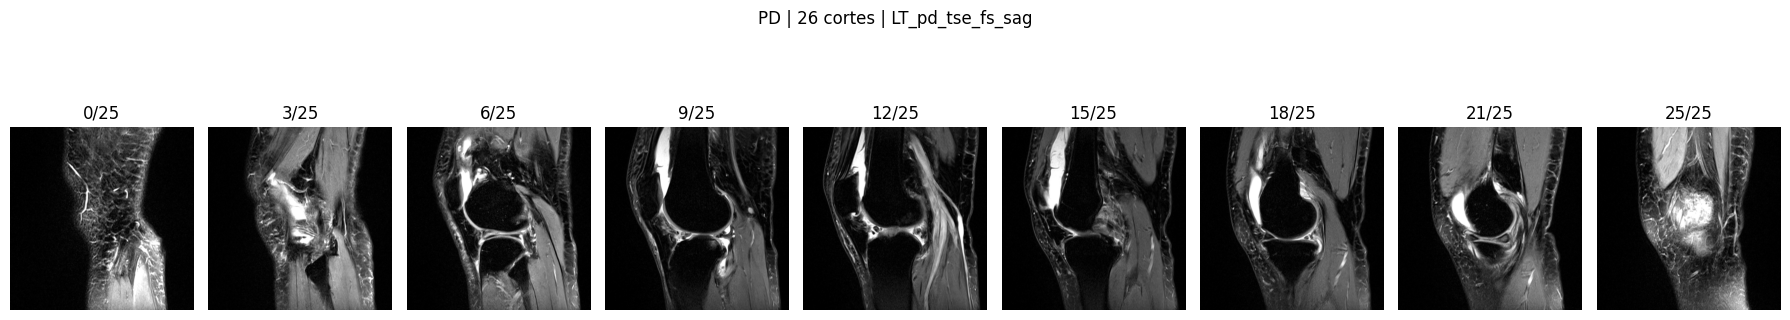


=== PD_like ===


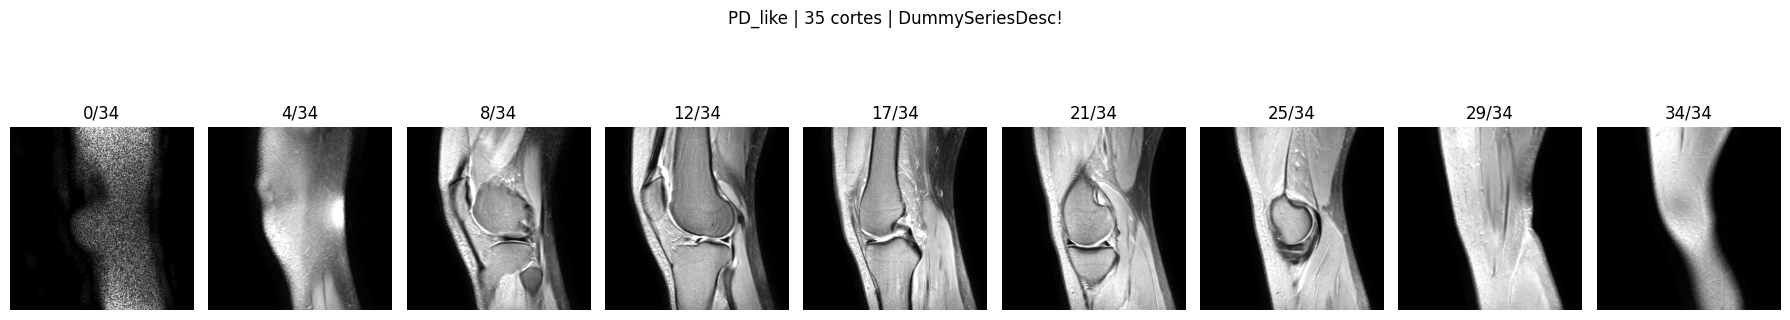


=== T2 ===


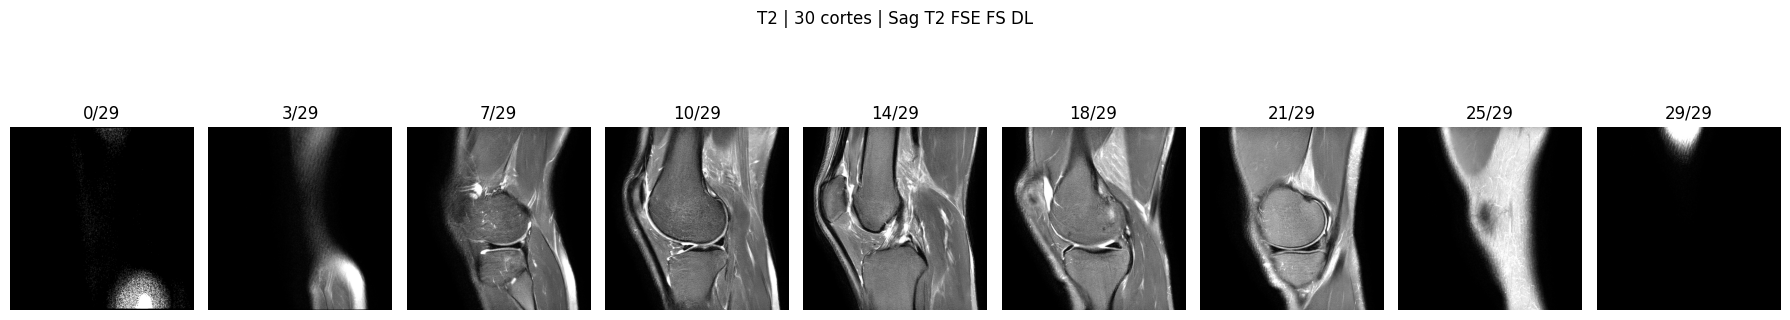


=== T2_like ===


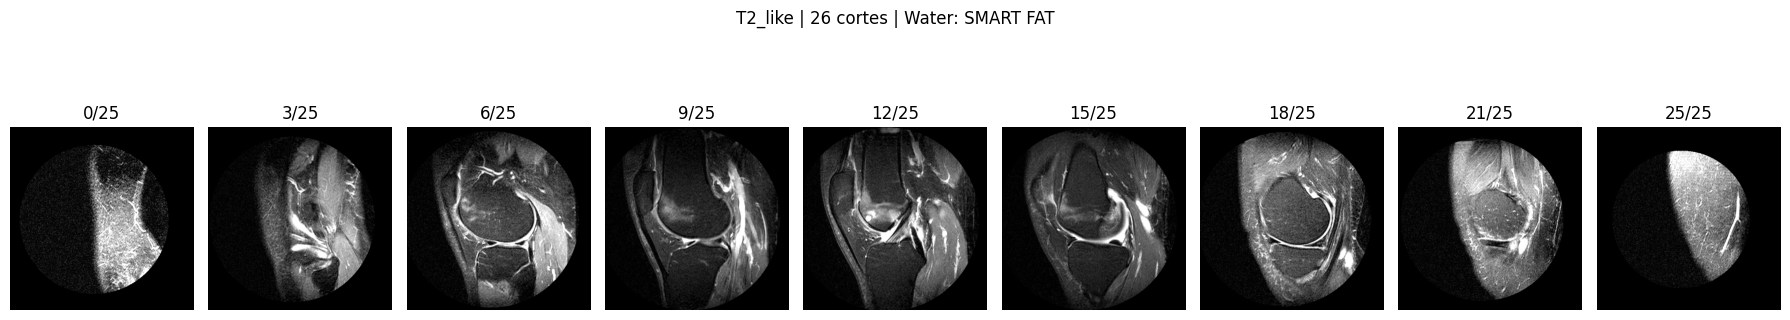


=== AMBIGUO ===


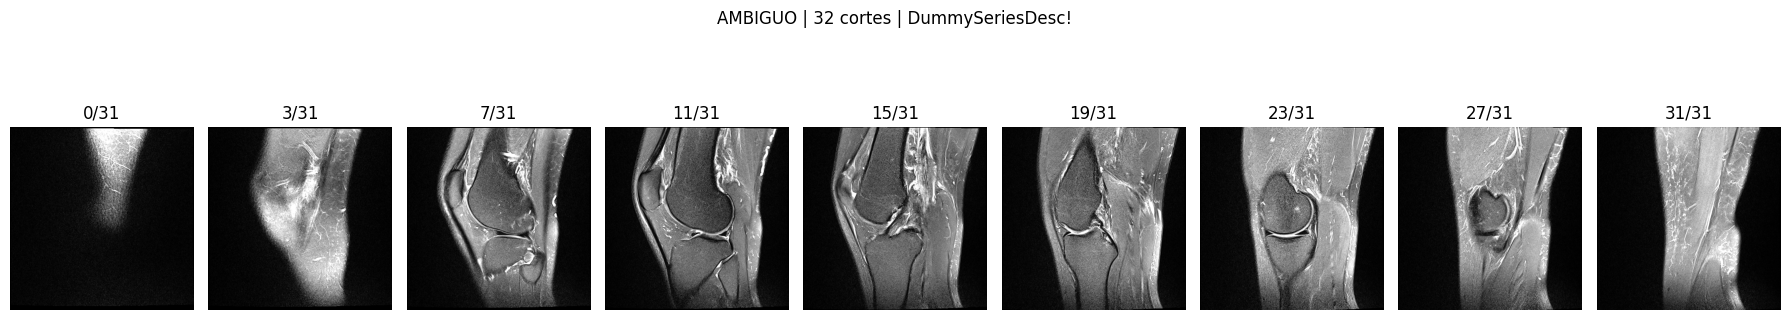

In [112]:
for tipo in [
    "PD",
    "PD_like",
    "T2",
    "T2_like",
    "AMBIGUO"
]:

    candidatos = seleccion_sag[
        seleccion_sag["Tipo_Final"]
        == tipo
    ]

    if len(candidatos) > 0:

        print(
            f"\n=== {tipo} ==="
        )

        mostrar_serie(
            candidatos.iloc[0]
        )

Study: 1.2.826.0.1.3680043.8.498.47094981922544354899183959858078311972
Cortes: 320
Descripción: SAG 3D_VIEW_PD_SPAIR_HR R


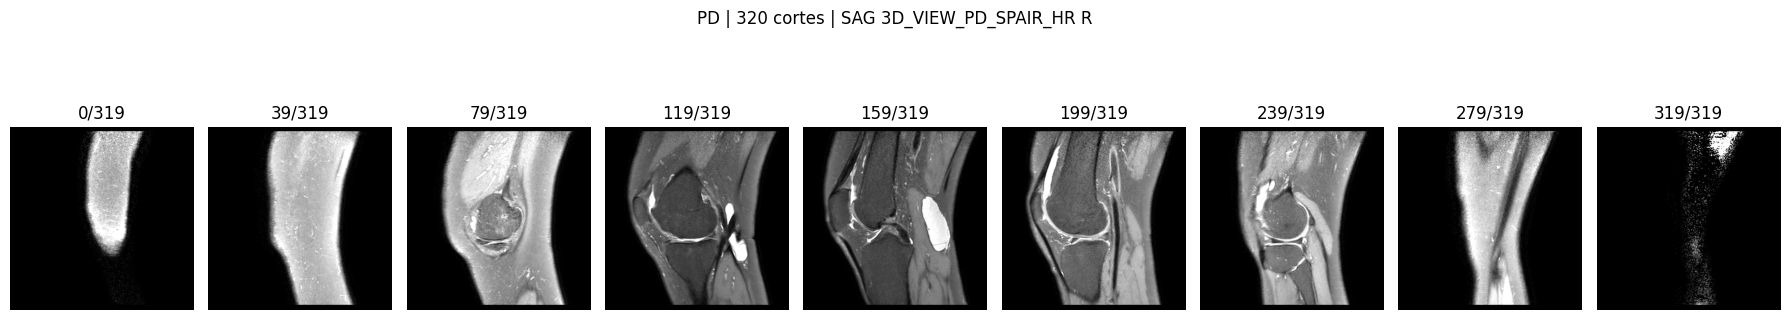

In [113]:
serie_3d = (
    seleccion_sag
    .sort_values(
        "N_Slices",
        ascending=False
    )
    .iloc[0]
)

print(
    "Study:",
    serie_3d["StudyInstanceUID"]
)

print(
    "Cortes:",
    serie_3d["N_Slices"]
)

print(
    "Descripción:",
    serie_3d["SeriesDescription"]
)

mostrar_serie(
    serie_3d
)

## 11. Conclusiones

A partir del subconjunto previamente construido de 500 estudios con
etiquetas débiles y de los 58 estudios GOLD, se analizaron las series
MRI disponibles mediante `train_series.csv`.

Se seleccionaron las series sagitales sensibles a líquido con supresión
de grasa como secuencia principal. Esta configuración presentó una
cobertura de 490/500 estudios weak y 56/58 estudios GOLD.

Debido a que algunos estudios contenían múltiples series candidatas,
se analizaron metadatos DICOM como `SeriesDescription`, `ProtocolName`,
`EchoTime`, número de cortes y parámetros espaciales. Se definió una
regla reproducible para seleccionar una única serie por estudio.

El resultado final fue un manifiesto de 546 estudios con una serie
sagital seleccionada por estudio:

- 490 estudios WEAK
- 56 estudios GOLD
- tamaño aproximado del subconjunto DICOM: 9.55 GB

Finalmente se realizó una inspección visual de ejemplos representativos
para verificar la coherencia anatómica y el orden de los cortes.

Este manifiesto será utilizado en la siguiente etapa para generar las
entradas 2.5D utilizadas por los modelos CNN.